<a href="https://colab.research.google.com/github/AfraazUlHaque/data-analytics/blob/main/K_MEAN(SCRATCH).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url = "https://raw.githubusercontent.com/sharmaroshan/Clustering-of-Mall-Customers/master/Mall_Customers.csv"


df = pd.read_csv(url)

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values

np.random.seed(42)

mean = X.mean(axis=0)
std = X.std(axis=0)

X = (X - mean) / std

class KMeans:

    def __init__(self, k=5, max_iter=100):
        self.k = k
        self.max_iter = max_iter

    def fit(self, X):

        indices = np.random.choice(
            len(X), self.k, replace=False
        )

        self.centroids = X[indices]

        for _ in range(self.max_iter):

            distances = np.sqrt(
                np.sum(
                    (X[:, np.newaxis] - self.centroids) ** 2,
                    axis=2
                )
            )

            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.array([
                X[self.labels == i].mean(axis=0)
                if np.any(self.labels == i)
                else self.centroids[i]
                for i in range(self.k)
            ])

            if np.allclose(self.centroids, new_centroids):
                break

            self.centroids = new_centroids

        return self

    def predict(self, X):

        distances = np.sqrt(
            np.sum(
                (X[:, np.newaxis] - self.centroids) ** 2,
                axis=2
            )
        )

        return np.argmin(distances, axis=1)


model = KMeans(k=5)

model.fit(X)

clusters = model.predict(X)

df["Cluster"] = clusters

print(df.head())

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster Centers:")
print(model.centroids * std + mean)


   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        2  
1        1  
2        2  
3        1  
4        2  

Cluster Distribution:
Cluster
0    80
1    22
2    23
3    39
4    36
Name: count, dtype: int64

Cluster Centers:
[[55.0875     49.7125    ]
 [25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [86.53846154 82.12820513]
 [87.75       17.58333333]]


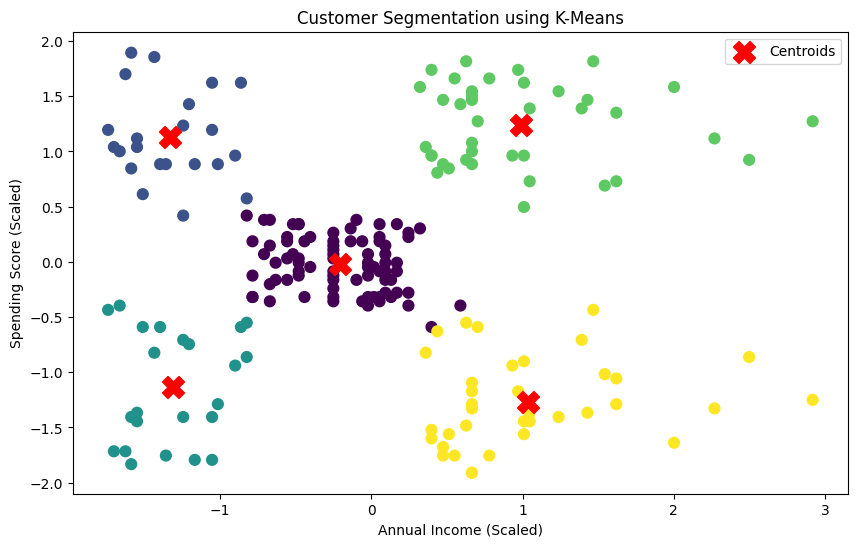

In [11]:

plt.figure(figsize=(10, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=clusters,
    cmap="viridis",
    s=60
)

plt.scatter(
    model.centroids[:, 0],
    model.centroids[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.legend()
plt.show()


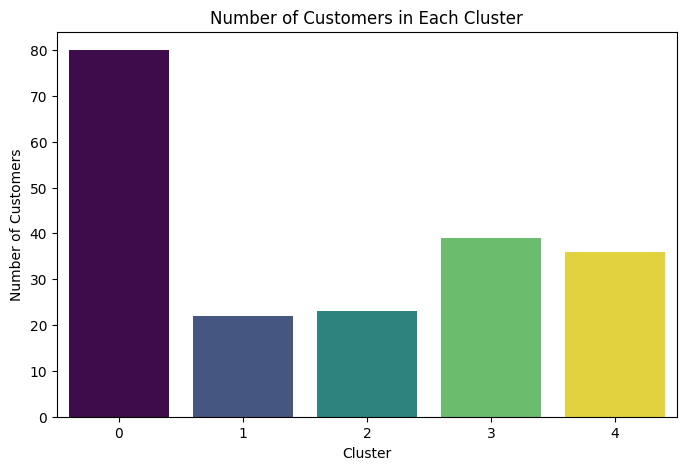

In [7]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()


               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        42.937500           55.087500               49.712500
1        25.272727           25.727273               79.363636
2        45.217391           26.304348               20.913043
3        32.692308           86.538462               82.128205
4        40.666667           87.750000               17.583333


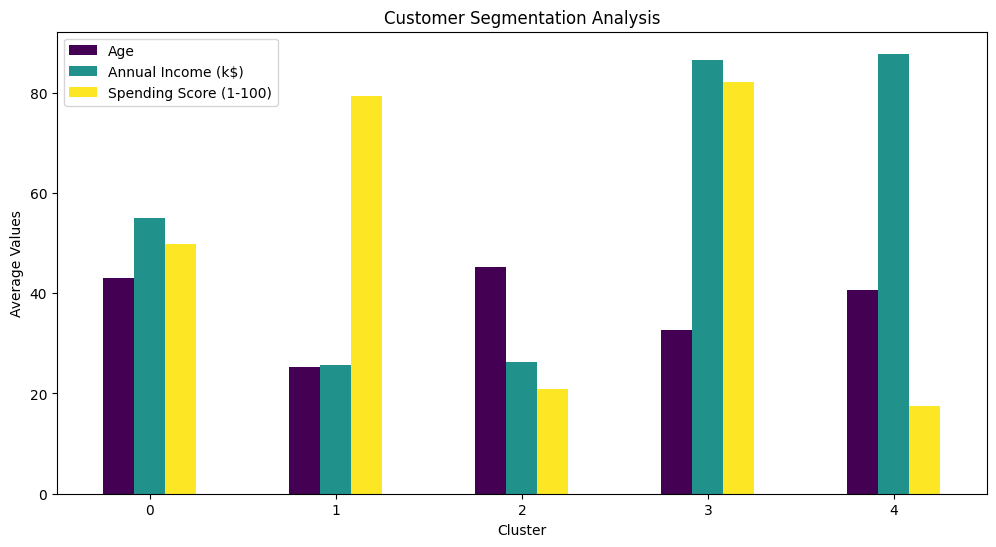

In [8]:

cluster_analysis = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean()

print(cluster_analysis)

cluster_analysis.plot(
    kind="bar",
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Customer Segmentation Analysis")
plt.ylabel("Average Values")
plt.xticks(rotation=0)
plt.show()


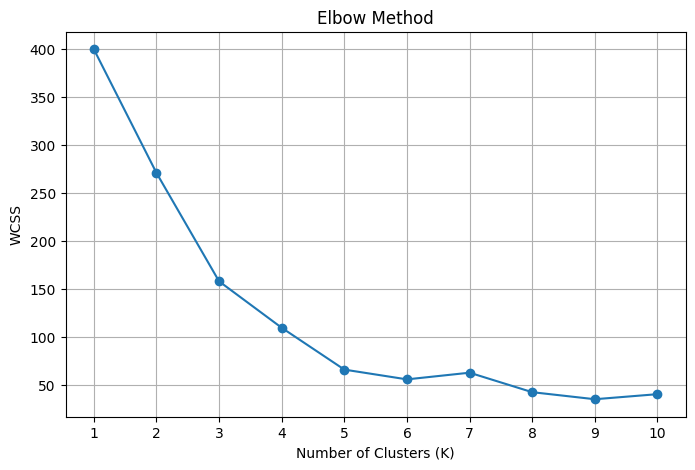

In [9]:

wcss = []

for k in range(1, 11):

    temp_model = KMeans(k=k)

    temp_model.fit(X)

    distances = np.sqrt(
        np.sum(
            (X - temp_model.centroids[temp_model.labels]) ** 2,
            axis=1
        )
    )

    wcss.append(np.sum(distances ** 2))

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid()
plt.show()
